## Bibliotecas

In [24]:
# Bibliotecas para silenciar advertencias
import warnings
warnings.filterwarnings('ignore') 

# Bibliotecas para manejo de datos
import numpy as np
import pandas as pd

# Bibliotecas para visualización
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib.colors as mcolors

# Bibliotecas para modelado
import shap # importamos SHAP para interprertación de modelos
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import KFold
from sklearn.model_selection import StratifiedKFold, cross_val_predict, GridSearchCV
from sklearn.inspection import permutation_importance
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVR
from sklearn.pipeline import Pipeline
from sklearn.metrics import (mean_squared_error, mean_absolute_error,
                             mean_absolute_percentage_error, r2_score)
from sklearn.base import clone

# Bibliotecas para expresiones regulares
import re

# Para manejo de rutas de archivos
from pathlib import Path

## Configuración de visualización

In [2]:
# Configuración de opciones de visualización
pd.set_option('display.max_columns', 60)
pd.set_option('display.width', 180)
sns.set_theme(style='whitegrid')

# Paleta: categórica en orden fijo + divergente azul-gris-naranja
AZUL, NARANJA, AQUA, AMARILLO = "#2a78d6", "#eb6834", "#1baf7a", "#eda100"
MORADO, ROSA, GRIS_CAT = "#7b5cd6", "#d6457f", "#8a8984"
GRIS_TXT, GRIS_EJE = "#52514e", "#898781"
COLOR_CONJ = {"ENTRENAMIENTO": AZUL, "PREDICCION": NARANJA}
COLOR_FAM = {"Fenología Planet": AZUL, "Fenología Sentinel-2": NARANJA, "Agroclima": AQUA, "ERA5-Land": AMARILLO,
             "Suelo": MORADO, "Topografía": ROSA, "Parcela": GRIS_CAT}
CMAP_DIV = mcolors.LinearSegmentedColormap.from_list("div", [AZUL, "#f0efec", NARANJA])

# Configuración de estilo de las gráficas
plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
    "axes.edgecolor": GRIS_EJE, "axes.labelcolor": GRIS_TXT,
    "xtick.color": GRIS_EJE, "ytick.color": GRIS_EJE,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "axes.axisbelow": True, "grid.color": "#e6e5e1", "grid.linewidth": 0.6,
    "axes.titleweight": "bold", "axes.titlesize": 11, "font.size": 9,
})

## Importación del Dataset

In [3]:
# Carpeta del proyecto
# Raíz del repositorio: se sube desde la carpeta actual hasta encontrar main.py
RAIZ = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "main.py").exists())
DATA_DIR = RAIZ / "data" / "modelado"

# Carga del dataset
df = pd.read_csv(DATA_DIR / 'dataset_modelo.csv')
print(f'Dataset cargado: {df.shape[0]} filas x {df.shape[1]} columnas')

Dataset cargado: 197 filas x 58 columnas


# **Modelo Ensamble Random Forest y Support Vectorial Regression**
## Selección de columnas (Línea base con ensayo de Random Forest y Ensamble SVR)
Derivado del análisis exploratorio, determinamos las siguientes acciones para un modelo de Ensamble SVR con 51 variables predictoras.

1. Como las 59 parcelas de predicción están en los mismos municipios que el entrenamiento, la CV aleatoria es válida para este split. 
2. Se creo una nueva variable `grupo_rend` a partir de clusterizar rendimientos_t_ha en Altos y Bajos, como una variable estratificadora de 5 splits para separar el efecto de zona.
3. No se consideran las variables predictoras con redundancias exactas (`pl_eos20_doy`, `ac_dias_lluvia_ciclo`, `pl_sos20_doy`, `era5_rs_ciclo_mj_m2`, `pend_p90_grados`, `s2_ndvi_int_abr_oct`, `pl_ndvi_pico`, `s2_centro_pico_doy`, `ac_lluvia_llen_mm`, `era5_apar_ciclo_mj_m2`, `ac_lluvia_ciclo_anom_mm`), eliminadas durante el preprocesamiento

Columnas definidas:
- **Metadatos:** `id_poligono`, `municipio`, `estado`, `conjunto`, `clima_pixel_id`
- **Variable objetivo:** `rendimiento_t_ha` (sin transformación: Random Forest no requiere normalidad)
- **Variables predictoras:** 51 variables (se excluyen las redundancias exactas)
- **Variable estratificadora:** `grupo_rend` (KMeans con 2 clusters sobre el rendimiento del set de entrenamiento)

## 1. Carga, roles de columnas y separación de conjuntos

Los roles se definen explícitamente para evitar *data leakage*:

| Rol | Columnas | Uso |
|---|---|---|
| Metadatos | `id_poligono`, `municipio`, `estado`, `conjunto`, `clima_pixel_id` | Identificación / reconstrucción final |
| Estratificación | `grupo_rend` | **Solo** para generar los cortes de `StratifiedKFold` |
| Objetivo | `rendimiento_t_ha` | `y` |
| Predictoras | Resto de columnas numéricas | `X` |

In [4]:
# Definición de columnas
cols_metadatos      = ['id_poligono', 'municipio', 'estado', 'conjunto', 'clima_pixel_id']
col_estratificacion = 'grupo_rend'
col_target          = 'rendimiento_t_ha'

cols_excluidas   = cols_metadatos + [col_estratificacion, col_target]
cols_predictoras = [c for c in df.columns
                    if c not in cols_excluidas and pd.api.types.is_numeric_dtype(df[c])]

# Verificaciones explícitas anti-fuga (data leakage)
assert not set(cols_predictoras) & set(cols_excluidas), 'Fuga: columnas excluidas dentro de X'
sin_rol = [c for c in df.columns if c not in cols_excluidas + cols_predictoras]
assert not sin_rol, f'Columnas sin rol asignado: {sin_rol}'

# Número de variables predictoras 
N_VARS = len(cols_predictoras)
print(f'Número de variables predictoras: {N_VARS}')

# Verificaciones explícitas anti-fuga (data leakage)
print(f'¿Metadatos en X? {bool(set(cols_metadatos) & set(cols_predictoras))} | '
      f"¿'{col_estratificacion}' en X? {col_estratificacion in cols_predictoras} | "
      f"¿'{col_target}' en X? {col_target in cols_predictoras}")

Número de variables predictoras: 51
¿Metadatos en X? False | ¿'grupo_rend' en X? False | ¿'rendimiento_t_ha' en X? False


### 1.1 Verificación de las 51 predictoras
Durante el preprocesamiento de datos se definieron **51** variables predictoras, se comprueba la lista de variables.

In [5]:
# Variables predictoras definidas en preprocesamiento
PREDICTORAS = [
    'area_ha_geod', 'elev_media_m', 'elev_std_m', 'pend_media_grados', 'pend_max_grados', 
    'dz_pixel_m', 'pl_n_picos', 'pl_sos50_doy', 'pl_centro_pico_doy', 'pl_eos50_doy', 
    'pl_dias_meseta', 'pl_caida_intra_ciclo', 'pl_ndvi_base', 'pl_amplitud', 'pl_integral_ciclo', 
    'pl_tasa_subida', 'pl_tasa_bajada', 'pl_ndvi_int_abr_oct', 'pl_lai_max_ciclo', 'pl_lai_int_ciclo', 
    's2_n_picos', 's2_sos50_doy', 's2_ndvi_pico', 's2_integral_ciclo', 'ac_lluvia_pre_mm',
    'ac_lluvia_veg_mm', 'ac_lluvia_ciclo_mm', 'ac_lluvia_max_dia_ciclo_mm', 'ac_racha_seca_max_flor', 'ac_racha_seca_max_ciclo', 
    'ac_gdd_ciclo', 'ac_gdd_hasta_flor', 'ac_balance_ciclo_mm', 'ac_balance_flor_mm', 'ac_balance_llen_mm', 
    'ac_lluvia_ciclo_anom_rel', 'soil_arcilla_pct', 'soil_arena_pct', 'soil_soc_g_kg', 'soil_densidad_g_cm3', 
    'soil_ph', 'soil_limo_pct', 'soil_agua_disp_mm', 'era5_tmax_media_flor_c', 'era5_vpd_medio_flor_kpa', 
    'era5_vpd_medio_llen_kpa', 'era5_sm1_siembra', 'era5_sm2_flor', 'era5_sm2_llen', 'era5_sm2_min_llen', 
    'era5_apar_post_pico_mj_m2'
 ]

# Verificación de que las columnas predictoras coinciden con las definidas en PREDICTORAS
print(f'{N_VARS} columnas en X:')
for i, c in enumerate(cols_predictoras, 1):
    print(f'  {i:2d}. {c:30s} ')

extra    = set(cols_predictoras) - set(PREDICTORAS)
faltante = set(PREDICTORAS) - set(cols_predictoras)
assert len(PREDICTORAS) == 51 and not extra and not faltante, f'extra={extra} | faltante={faltante}'
print(f'\nX = 51 PREDICTORAS = {N_VARS} columnas; sin variables indebidas.')

51 columnas en X:
   1. area_ha_geod                   
   2. elev_media_m                   
   3. elev_std_m                     
   4. pend_media_grados              
   5. pend_max_grados                
   6. dz_pixel_m                     
   7. pl_n_picos                     
   8. pl_sos50_doy                   
   9. pl_centro_pico_doy             
  10. pl_eos50_doy                   
  11. pl_dias_meseta                 
  12. pl_caida_intra_ciclo           
  13. pl_ndvi_base                   
  14. pl_amplitud                    
  15. pl_integral_ciclo              
  16. pl_tasa_subida                 
  17. pl_tasa_bajada                 
  18. pl_ndvi_int_abr_oct            
  19. pl_lai_max_ciclo               
  20. pl_lai_int_ciclo               
  21. s2_n_picos                     
  22. s2_sos50_doy                   
  23. s2_ndvi_pico                   
  24. s2_integral_ciclo              
  25. ac_lluvia_pre_mm               
  26. ac_lluvia_veg_mm          

### 1.2 Definimos los conjuntos de entrenamiento y predicción

In [6]:
# Separación de conjuntos de entrenamiento y predicción
df_train = df[df['conjunto'] == 'ENTRENAMIENTO'].copy()
df_pred  = df[df['conjunto'] == 'PREDICCION'].copy()
assert len(df_train) == 138 and len(df_pred) == 59

# Preparación de matrices para modelado
X_train = df_train[cols_predictoras]
y_train = df_train[col_target]
X_pred  = df_pred[cols_predictoras]

# Verificación de NaN en predictoras y target
assert X_train.notna().all().all() and X_pred.notna().all().all(), 'Hay NaN en predictoras'
assert y_train.notna().all(), 'Hay NaN en target'

# Imprimir dimensiones de los conjuntos
print(f'df_train: {df_train.shape} | X_train: {X_train.shape} | y_train: {y_train.shape}')
print(f'df_pred : {df_pred.shape} | X_pred : {X_pred.shape}')
print('\nDistribución de grupo_rend (entrenamiento):')
print(df_train[col_estratificacion].value_counts().to_string())

df_train: (138, 58) | X_train: (138, 51) | y_train: (138,)
df_pred : (59, 58) | X_pred : (59, 51)

Distribución de grupo_rend (entrenamiento):
grupo_rend
Alto    80
Bajo    58


## 2. Modelos Predictivos 
### 2.1 Definición de Estratifición
`StratifiedKFold(5)` estratificado por la variable `grupo_rend`. Los **mismos** `cv_splits` se reutilizan en todo el notebook.



In [7]:
# Validación cruzada estratificada
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
cv_splits = list(skf.split(df_train[cols_predictoras], df_train[col_estratificacion]))

# Función para mostrar los pliegues de la validación cruzada
def mostrar_pliegues(splits, df_train):
    for i, (tr, va) in enumerate(splits, 1):
        print(f'Pliegue {i}: train={len(tr):3d} | val={len(va):2d} | '
              f"val Alto/Bajo = {df_train['grupo_rend'].iloc[va].value_counts().to_dict()}")

# Imprimir los pliegues de la validación cruzada
mostrar_pliegues(cv_splits, df_train)

Pliegue 1: train=110 | val=28 | val Alto/Bajo = {'Alto': 16, 'Bajo': 12}
Pliegue 2: train=110 | val=28 | val Alto/Bajo = {'Alto': 16, 'Bajo': 12}
Pliegue 3: train=110 | val=28 | val Alto/Bajo = {'Alto': 16, 'Bajo': 12}
Pliegue 4: train=111 | val=27 | val Alto/Bajo = {'Alto': 16, 'Bajo': 11}
Pliegue 5: train=111 | val=27 | val Alto/Bajo = {'Alto': 16, 'Bajo': 11}


### Interpretaciones
Confirmamos que todos los pliegues tiene el mismo tamaño y exactamente la misma proporción de clases.

## **2.1 Modelo 1: Random Forest con Permutation Importance Out-of-Fold (OOF)**
Derivado de los resultados obtenidos en el EDA, con respecto al ensayo de un modelo con Random Forest (62 variables predictoras, usando Kfold), validamos un primer modelo, utilizando Permutation Importance out-of-fold (OOF) lo que genera un ranking para encontrar las variables de mayor importancia.

**Diccionario de parámetros**:
Se considerarón valores estándar para después ajustarlos con respaldo empírico.
- n_estimators: 500 — El bosque estará compuesto por 500 árboles de decisión individuales.
- max_depth: 6 — Cada árbol tendrá una profundidad máxima de 5 niveles. (Limitamos la complejidad del modelo y evitamos el sobreajustarlo).
- min_samples_leaf: 3 — Cada nudo final (hoja) de un árbol debe contener al menos 4 observaciones. (Evitamos crear reglas para casos aislados)
- max_features: 'sqrt' — Se busca la mejor división en cada nodo, el algoritmo solo evaluará una cantidad de variables igual a la raíz cuadrada del total de variables predictoras. (Aseguramos diversidad entre arboles).
- max_samples: 0.8 — Cada árbol se entrenará usando una muestra aleatoria del 85% de los datos de entrenamiento.
- random_state: 42 — Fijamos una semilla aleatoria para garantizar que cada vez que se ejecute el código, se obtengan exactamente los mismos resultados.
- n_jobs: -1 — Utilizamos todos los núcleos disponibles del procesador de la computadora para entrenar los árboles en paralelo y acelerar el cálculo.

## Selección de Características y Búsqueda del Subconjunto Óptimo

Para evitar sesgos y asegurar que el modelo generalice correctamente (evitar sobreajuste), implementamos un flujo de ingeniería de características basado en validación cruzada:

1. **Importancia por Permutación Out-of-Fold (OOF):** 
   Utilizamos un `RandomForestRegressor` para calcular la importancia de las variables mediante *Permutation Importance* evaluada solamente en los datos de validación de cada pliegue (*fold*). Esto nos da un ranking y aseguramos que no haya sobreajuste.
2. **Búsqueda Forward (*Forward Selection*):** 
   Evaluamos subconjuntos incrementales de variables predictoras(desde $k = 5$ hasta $k = 25$) ordenados por su importancia OOF .
3. **Métricas de Evaluación:** 
   Cada subconjunto se evalúa utilizando validación cruzada para medir su rendimiento real mediante el Error Cuadrático Medio de la Raíz (**RMSE**), el Error Absoluto Medio (**MAE**) y el Coeficiente de Determinación ($R^2$) y se elige el subconjunto optimo de variables predictoras que menor RMSE tenga. 

In [8]:
# Ranking robusto mediante Permutation Importance Out-of-Fold (OOF)
rf_ranker = RandomForestRegressor(
    n_estimators=500, max_features='sqrt', min_samples_leaf=3,
    max_depth=6, max_samples=0.8, random_state=42, n_jobs=-1
)

# Calculamos la importancia de las variables mediante Permutation Importance OOF
importancias_oof = np.zeros(len(cols_predictoras)) # Inicializamos el vector de importancias
for train_idx, val_idx in cv_splits:
    X_tr, y_tr = df_train[cols_predictoras].iloc[train_idx], y_train.iloc[train_idx]
    X_va, y_va = df_train[cols_predictoras].iloc[val_idx], y_train.iloc[val_idx]

    rf_ranker.fit(X_tr, y_tr)
    perm = permutation_importance(
        rf_ranker, X_va, y_va, n_repeats=15, random_state=42, scoring='neg_root_mean_squared_error', n_jobs=-1
    )
    importancias_oof += perm.importances_mean / len(cv_splits)

# Creamos un ranking de las variables basado en la importancia promedio OOF
ranking_vars = pd.Series(importancias_oof, index=cols_predictoras).sort_values(ascending=False)
print("\nTop 15 variables por Permutación (OOF):")
print(ranking_vars.head(15).round(4))

# Búsqueda Forward del tamaño óptimo de subconjunto (de 5 a 25 variables predictoras)
resultados_k = []
for k in range(5, min(26, len(cols_predictoras) + 1)):
    sub_vars = ranking_vars.index[:k].tolist()
    y_hat_k = cross_val_predict(rf_ranker, df_train[sub_vars], y_train, cv=cv_splits, n_jobs=-1)
    rmse_k = np.sqrt(mean_squared_error(y_train, y_hat_k))
    mae_k = mean_absolute_error(y_train, y_hat_k)
    r2_k = r2_score(y_train, y_hat_k)
    resultados_k.append({'k': k, 'RMSE': rmse_k, 'MAE': mae_k, 'R2': r2_k, 'vars': sub_vars})

# Creamos un DataFrame con los resultados
df_k = pd.DataFrame(resultados_k)

# Identificamos el subconjunto óptimo basado en RMSE mínimo
mejor_fila = df_k.loc[df_k['RMSE'].idxmin()]
vars_optimas = mejor_fila['vars']

# Impresión de los resultados del subconjunto óptimo
print(f"\Subconjunto óptimo encontrado: {int(mejor_fila['k'])} variables")
print(f"R²: {mejor_fila['R2']:.3f} | MAE: {mejor_fila['MAE']:.3f} | RMSE: {mejor_fila['RMSE']:.3f} t/ha")
print("Variables seleccionadas:", vars_optimas)


Top 15 variables por Permutación (OOF):
era5_vpd_medio_flor_kpa       0.0540
ac_lluvia_pre_mm              0.0240
era5_sm2_flor                 0.0193
ac_balance_flor_mm            0.0119
era5_vpd_medio_llen_kpa       0.0085
ac_balance_ciclo_mm           0.0080
ac_gdd_ciclo                  0.0079
pl_eos50_doy                  0.0079
ac_lluvia_max_dia_ciclo_mm    0.0078
ac_lluvia_ciclo_anom_rel      0.0076
soil_agua_disp_mm             0.0074
pend_media_grados             0.0048
soil_soc_g_kg                 0.0045
ac_lluvia_ciclo_mm            0.0035
elev_media_m                  0.0031
dtype: float64

SUBCONJUNTO ÓPTIMO ENCONTRADO: 19 variables
R²: 0.586 | MAE: 0.416 | RMSE: 0.546 t/ha
Variables seleccionadas: ['era5_vpd_medio_flor_kpa', 'ac_lluvia_pre_mm', 'era5_sm2_flor', 'ac_balance_flor_mm', 'era5_vpd_medio_llen_kpa', 'ac_balance_ciclo_mm', 'ac_gdd_ciclo', 'pl_eos50_doy', 'ac_lluvia_max_dia_ciclo_mm', 'ac_lluvia_ciclo_anom_rel', 'soil_agua_disp_mm', 'pend_media_grados', 'soil_so

### Interpretaciones

* **Subconjunto Óptimo Seleccionado:** 
  El algoritmo identificó que el mejor rendimiento se obtiene utilizando un total de 19 variables predictoras, dichas variables maximizan la capacidad predictiva sin sobrecargar el modelo con ruido.
* **Métricas de Rendimiento (Validación OOF):**
  * **$R^2$:** Indica el porcentaje de variabilidad del rendimiento agrícola explicado por el modelo, en este caso 0.586.
  * **RMSE y MAE:** Muestran el margen de error promedio en las unidades originales de la variable objetivo (`t/ha`), lo que nos permite conocer la precisión del modelo, en esta caso RMSE = 0.546 y MAE = 0.416.
* **Sobreajuste (*Overfitting*):**
Para saber si hemos sobreajustado el modelo, 

## **2.3 Modelo 2: Random Forest con ajuste de hiperparámetros mediante GridSearchCV**
Con el subconjunto óptimo (`vars_optimas`, 19 variables predictoras) obtenidas en el modelo 1, se ajustan los hiperparámetros del Random Forest con `GridSearchCV` sobre los mismos `cv_splits`. En esta ocasión, incorporamos el desglose del error OOF por municipio para detectar sesgos.

- `GridSearchCV`nos ayuda a probar todas las combinaciones de hiperparámetros posibles utilizando la validacion y elegir el mejor modelo de random forest con la mejor combinación de hiperparámetros.
    - Esto lo hace mediante la evaluación con `neg_root_mean_squared_error` (Raíz del Error Cuadrático Medio Negativo), entre más cercano a 0 mejor.
- `cross_val_predict` nos ayuda a realizar la validación cruzada con los cv_splits definidos al inicio.

In [15]:
# Ajuste de hiperparámetros de RF sobre el subconjunto óptimo
param_grid_rf = {
    'n_estimators': [500],
    'max_features': ['sqrt', 0.3, 0.4, 0.5],
    'min_samples_leaf': [2, 3, 4],
    'max_depth': [5, 6, 8, None],
    'max_samples': [0.75, 0.85, 1.0]
}

# Búsqueda de hiperparámetros
grid_rf = GridSearchCV(
    RandomForestRegressor(random_state=42, n_jobs=-1),
    param_grid_rf, cv=cv_splits, scoring='neg_root_mean_squared_error', n_jobs=-1
)
# Ajuste del modelo RF con el subconjunto óptimo de variables y búsqueda de hiperparámetros
grid_rf.fit(df_train[vars_optimas], y_train)
best_rf = grid_rf.best_estimator_
print("Mejores hiperparámetros RF:", grid_rf.best_params_)

# Predicciones Out-of-Fold del RF optimizado
oof_rf = cross_val_predict(best_rf, df_train[vars_optimas], y_train, cv=cv_splits, n_jobs=-1)

# Tabla de diagnóstico de residuos por municipio
df_residuos = pd.DataFrame({
    'municipio': df_train['municipio'],
    'grupo_rend': df_train[col_estratificacion],
    'y_real': y_train,
    'y_pred_rf': oof_rf,
    'residuo': y_train - oof_rf,          # Positivo = Modelo subestima | Negativo = Modelo sobreestima
    'error_abs': np.abs(y_train - oof_rf),
    'error_cuad': (y_train - oof_rf) ** 2
})

# Resumen de errores por municipio
resumen_mun = df_residuos.groupby('municipio').agg(
    n_parcelas=('y_real', 'count'),
    media_real=('y_real', 'mean'),
    media_pred=('y_pred_rf', 'mean'),
    sesgo_medio=('residuo', 'mean'),
    MAE=('error_abs', 'mean'),
    RMSE=('error_cuad', lambda x: np.sqrt(np.mean(x)))
).sort_values(by='n_parcelas', ascending=False)

print("\nDiagnóstico de errores por municipio (Random Forest con GridSearchCV)")
print(resumen_mun.round(3))

# Cálculo de métricas globales OOF
rmse_modelo2 = np.sqrt(mean_squared_error(y_train, oof_rf))
mae_modelo2 = mean_absolute_error(y_train, oof_rf)
r2_modelo2 = r2_score(y_train, oof_rf)

print("\nMétricas globales del modelo 2. Random Forest con GridSearchCV (OOF)")
print(f"RMSE Global: {rmse_modelo2:.3f}")
print(f"MAE Global:  {mae_modelo2:.3f}")
print(f"R² Global:   {r2_modelo2:.3f}")

Mejores hiperparámetros RF: {'max_depth': 5, 'max_features': 'sqrt', 'max_samples': 1.0, 'min_samples_leaf': 2, 'n_estimators': 500}

Diagnóstico de errores por municipio (Random Forest con GridSearchCV)
                               n_parcelas  media_real  media_pred  sesgo_medio    MAE   RMSE
municipio                                                                                   
Chignahuapan                           71       4.477       4.423        0.054  0.422  0.595
Calpulalpan                            30       3.000       3.152       -0.152  0.370  0.439
Singuilucan                            16       3.081       3.376       -0.294  0.358  0.503
Almoloya                               10       4.521       4.149        0.372  0.372  0.424
Cuautepec de Hinojosa                   5       4.598       4.169        0.429  0.429  0.488
Emiliano Zapata                         3       3.500       3.225        0.275  0.275  0.278
Apan                                    1       3.00

### Interpretaciones

Los municipios Emiliano Zapata, Apan, Nanacamilpa de Mariano Arista y Tepeapulc presentan valores marginales de parcelas, por lo que, podriamos considerarlos estadísticamente poco representativos

## **2.4 Modelo 3: Ensamble por Blending: Random Forest con Support Vectorial Regression (SVR)**
El SVR con kernel RBF complementa al Random Forest, esto se explica ya que el Random Forest hace cortes ortogonales (escalones) y no suaviza tendencias continuas, mientras que el SVR ajusta una superficie suave que maneja bien la transición entre los regímenes de rendimiento bajo y alto. 

En este apartado realizamos el entrenamiento, optimización de hiperparámetros, validación cruzada y combinación (ensamble por blending) de un modelo de Regresión de Vectores de Soporte (SVR), posteriormente lo comparamos con el mMdelo 2 de Random Forest con GridSearchCV.

De manera que obtendremos la comparación de métricas de 3 modelos:
1. Modelo 2. Random Forest con GridSerachCV
2. Modelo de prueba. Regresión de Vectores de Soporte (SVR)
3. Modelo 3. Ensamble por Blending: Combinación de ambos modelos

In [16]:
# Pipeline de SVR (escalado dentro de cada pliegue para evitar data leakage)
pipe_svr = Pipeline([
    ('scaler', StandardScaler()), # StandardScaler para que se ajuste solo con el pliegue de entrenamiento.
    ('svr', SVR(kernel='rbf'))
])

# Grilla enfocada en regularización suave para 138 observaciones
param_grid_svr = {
    'svr__C': [0.5, 1.0, 2.0, 5.0, 10.0],
    'svr__epsilon': [0.05, 0.1, 0.2, 0.3],
    'svr__gamma': ['scale', 'auto', 0.01, 0.05, 0.1]
}

grid_svr = GridSearchCV(
    pipe_svr, param_grid_svr, cv=cv_splits, scoring='neg_root_mean_squared_error', n_jobs=-1
)
grid_svr.fit(df_train[vars_optimas], y_train)
best_svr = grid_svr.best_estimator_
print("Mejores hiperparámetros para SVR:", grid_svr.best_params_)

# Predicciones Out-of-Fold del SVR
oof_svr = cross_val_predict(best_svr, df_train[vars_optimas], y_train, cv=cv_splits, n_jobs=-1)

# Optimización del peso de Blending: y_blend = w * RF + (1 - w) * SVR
mejor_w, mejor_rmse_blend = 0.5, float('inf')
for w in np.linspace(0, 1, 101):
    blend_temp = w * oof_rf + (1 - w) * oof_svr
    rmse_temp = np.sqrt(mean_squared_error(y_train, blend_temp))
    if rmse_temp < mejor_rmse_blend:
        mejor_rmse_blend = rmse_temp
        mejor_w = w

oof_blend = mejor_w * oof_rf + (1 - mejor_w) * oof_svr

# Comparativa de métricas Out-of-Fold
def imprimir_metricas(nombre, y_true, y_pred):
    r2 = r2_score(y_true, y_pred)
    mae = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    print(f"{nombre:<34} -> R²: {r2:.3f} | MAE: {mae:.3f} | RMSE: {rmse:.3f} t/ha")

# Comparativa de modelos
print("\nComparativa de modelos (5-Fold Estratificado por grupo_rend, 19 variables)")
imprimir_metricas("Modelo 2. Random Forest con GridSearchCV", y_train, oof_rf)
imprimir_metricas("Modelo de Prueba. SVR (StandardScaler+RBF)", y_train, oof_svr)
imprimir_metricas(f"Modelo 3. Ensamble ({mejor_w:.2f} RF + {1-mejor_w:.2f} SVR)", y_train, oof_blend)

Mejores hiperparámetros para SVR: {'svr__C': 10.0, 'svr__epsilon': 0.3, 'svr__gamma': 0.01}

Comparativa de modelos (5-Fold Estratificado por grupo_rend, 19 variables)
Modelo 2. Random Forest con GridSearchCV -> R²: 0.601 | MAE: 0.401 | RMSE: 0.536 t/ha
Modelo de Prueba. SVR (StandardScaler+RBF) -> R²: 0.638 | MAE: 0.390 | RMSE: 0.510 t/ha
Modelo 3. Ensamble (0.27 RF + 0.73 SVR) -> R²: 0.644 | MAE: 0.386 | RMSE: 0.506 t/ha


### Interpretaciones:

Podemos observar que el modelo SVR (StandardScaler+RBF) por si solo logró mejorar sus métricas de evaluación con respecto al modelo 2. 

Además, se puede observar que nuestras métricas de evaluación mejoraron en el Modelo 3 con respecto a los otros. Subimos la capacidad predictiva($R^2$) en $7.15\%$, disminuimos el error absoluto medio(MAE) en $3.74\%$ y redujimos la raíz del error cuadrático medio(RMSE) en $5.60\%$.

Al combinar ambos enfoques asignando un 27% de peso a Random Forest y un 73% a SVR, se obtiene el mejor rendimiento global. Este modelo maximiza la precisión con un $R^2$ de 0.644 y minimiza el error de predicción a un MAE de 0.386 y un RMSE de 0.506 t/ha. 

Aprovechamos la alta capacidad de generalización del SVR optimizado y la complementamos con el modelo 2. Random Forest con GridSearchCV para reducir el error de estimación del rendimiento.

Por lo que nuestro modelo 3 resulta ser la opción más solida hasta el momento.

## **2.5 Corrección de sesgo por municipio**
Se compara el sesgo por municipio del Modelo 2. Random Forest contra el Modelo 3. Ensamble y se evalúa si quitar alguna de las 19 variables (p. ej. lluvias redundantes, que dominan la distancia euclidiana del kernel RBF) baja aún más el RMSE del Ensamble. Solo se elimina una variable si mejora el RMSE en más de 0.001 t/ha.

In [18]:
# Diagnóstico por municipio comparando RF vs. Ensamble (19 variables)
df_comparativa_mun = pd.DataFrame({
    'municipio': df_train['municipio'],
    'y_real': y_train,
    'pred_rf': oof_rf,
    'pred_ensamble': oof_blend,
    'sesgo_rf': y_train - oof_rf,
    'sesgo_ensamble': y_train - oof_blend,
    'err_abs_ensamble': np.abs(y_train - oof_blend),
    'err_cuad_ensamble': (y_train - oof_blend) ** 2
})

# Resumen de errores por municipio para el Ensamble
tabla_mun_ensamble = df_comparativa_mun.groupby('municipio').agg(
    n_parcelas=('y_real', 'count'),
    media_real=('y_real', 'mean'),
    media_ensamble=('pred_ensamble', 'mean'),
    sesgo_RF=('sesgo_rf', 'mean'),
    sesgo_Ensamble=('sesgo_ensamble', 'mean'),
    MAE_Ensamble=('err_abs_ensamble', 'mean'),
    RMSE_Ensamble=('err_cuad_ensamble', lambda x: np.sqrt(np.mean(x)))
).sort_values(by='n_parcelas', ascending=False)

print("Corección de sesgo por municipio: Modelo 2. Random Forest en comparación con Modelo 3.Ensamble por Blending")
print(tabla_mun_ensamble.round(3))

Corección de sesgo por municipio: Modelo 2. Random Forest en comparación con Modelo 3.Ensamble por Blending
                               n_parcelas  media_real  media_ensamble  sesgo_RF  sesgo_Ensamble  MAE_Ensamble  RMSE_Ensamble
municipio                                                                                                                   
Chignahuapan                           71       4.477           4.487     0.054          -0.009         0.413          0.569
Calpulalpan                            30       3.000           3.131    -0.152          -0.131         0.386          0.447
Singuilucan                            16       3.081           3.169    -0.294          -0.087         0.347          0.449
Almoloya                               10       4.521           4.264     0.372           0.257         0.272          0.317
Cuautepec de Hinojosa                   5       4.598           4.213     0.429           0.385         0.385          0.475
Emiliano Zapata  

### Interpretaciones

Los municipios de Chignahuapan (71 parcelas) y Calpulalpan (30 parcelas) al concentrar el mayor número de parcelas, proporcionan un MAE y RMSE más estable, ya que hay más muestras.

Con el Modelo 3. Ensamble con Blending se logró reducir el sesgo, por ejemplo, para el municipio de Singuilucan (16 parcelas) pasamos de un segos en el Modelo 2. del -0.294 a -0.087. Para el caso de Chignahuapan, el sesgo es casi 0.
Vale la pena mencionar los 3 municipios que unicamente tienen 3 y 1  observación cada uno (Emiliano Zapata, Apan, Nanacamilpa de Mariano Arista y Tepeapulco respectivamente), ya que podriamos considerarlos estadisticamente poco representativos, además de que los modelos solo aprenden con una sola observación.

## **2.6 Modelo 4. Ensamble con Blending + Selección de Variables con (Sequential Backward Elimination)**

Para el modelo 4, utilizamos el Modelo 3. Ensamble con Blending (Random Forest con GridSearchCV + SVR (StandardScaler+RBF))
y realizamos una selección de variables con el método Sequential Backward Elimination.

Lo que hace este método es:
1. Utiliza las 19 variables predictoras del Modelo 3.
2. Itera sobre cada una de ellas, en cada iteración, se prueba eliminar variable por variable.
3. En cada iteración, entrena y predice con validación cruzada al modelo 2. y el SVR que se uso en el modelo 3 y los combina con el peso óptimo.
4. Se calcula el nuevo RMSE (con la variable excluida dentro del paso 2)
5. Ordena las variables predictoras de acuerdo al RMSE obtenido y selecciona la variable predictora que disminuye el error al ser eliminada.
6. Se repite el ciclo hasta que eliminar una variable más no signifique una mejora real en el modelo (en este caso, reducir 0.001 el RMSE)


In [19]:
# Selección de variables SBE sobre las 19 variables del Modelo 3. 
vars_actuales = list(vars_optimas)
mejor_rmse_global = np.sqrt(mean_squared_error(y_train, oof_blend))

print()
# bucle de poda SBE (Sequential Backward Elimination) para el Ensamble
while len(vars_actuales) > 8:
    candidatos_drop = []
    for v in vars_actuales:
        sub = [col for col in vars_actuales if col != v]
        oof_rf_sub = cross_val_predict(best_rf, df_train[sub], y_train, cv=cv_splits, n_jobs=-1)
        oof_svr_sub = cross_val_predict(best_svr, df_train[sub], y_train, cv=cv_splits, n_jobs=-1)
        oof_blend_sub = mejor_w * oof_rf_sub + (1 - mejor_w) * oof_svr_sub
        rmse_sub = np.sqrt(mean_squared_error(y_train, oof_blend_sub))
        candidatos_drop.append((rmse_sub, v, oof_blend_sub))

    candidatos_drop.sort(key=lambda x: x[0])
    mejor_rmse_paso, var_eliminada, mejor_oof_paso = candidatos_drop[0]

    if mejor_rmse_paso < mejor_rmse_global - 0.001:  # Mejora real en RMSE
        mejor_rmse_global = mejor_rmse_paso
        vars_actuales.remove(var_eliminada)
        oof_blend_opt = mejor_oof_paso
        print(f"[-] Eliminada: {var_eliminada:<28} -> Nuevo RMSE Ensamble: {mejor_rmse_global:.4f} t/ha | R²: {r2_score(y_train, oof_blend_opt):.3f}")
    else:
        break

# Impresión del subconjunto definitivo tras selección de variables
print(f"\nSubconjunto definitivo tras selección de variables para Ensamble ({len(vars_actuales)} variables):")
print(vars_actuales)


[-] Eliminada: soil_agua_disp_mm            -> Nuevo RMSE Ensamble: 0.4960 t/ha | R²: 0.658
[-] Eliminada: soil_soc_g_kg                -> Nuevo RMSE Ensamble: 0.4883 t/ha | R²: 0.668
[-] Eliminada: ac_lluvia_pre_mm             -> Nuevo RMSE Ensamble: 0.4861 t/ha | R²: 0.671

Subconjunto definitivo tras selección de variables para Ensamble (16 variables):
['era5_vpd_medio_flor_kpa', 'era5_sm2_flor', 'ac_balance_flor_mm', 'era5_vpd_medio_llen_kpa', 'ac_balance_ciclo_mm', 'ac_gdd_ciclo', 'pl_eos50_doy', 'ac_lluvia_max_dia_ciclo_mm', 'ac_lluvia_ciclo_anom_rel', 'pend_media_grados', 'ac_lluvia_ciclo_mm', 'elev_media_m', 'soil_arcilla_pct', 'area_ha_geod', 'pl_ndvi_int_abr_oct', 'pl_lai_int_ciclo']


### Interpretaciones

Como podemos observar, eliminar las variables `soil_agua_disp_mm` (agua disponible en el suelo), `soil_soc_g_kg` (carbono orgánico del suelo) y `ac_lluvia_pre_mm` (lluvia acumulada previa), logramos disminuir el RMSE, además de mejorar la capacidad predictiva($R^2$) hasta 0.671.

## **2.7 Modelo 5. Ensamble Final (Re-calibración sobre las 16 variables)**
Durante la selección de variables llevada a cabo en el Modelo 4., `best_rf`, `best_svr` y `mejor_w` estaban calibrados para 19 variables. Con las 16 variables predictoras finales, repetimos el `GridSearchCV` de ambos modelos y la búsqueda del peso `w`, se entrena con las 138 parcelas.

Que hacemos en este apartado:
1. Utilizamos las 16 variables predictoras del Modelo 4. 
2. Se calibran los hiperparámetros con GridSearchCV para Modelo 2. y Modelo SVR, mediante validación cruzada y con el objetivo de minimizar `neg_root_mean_squared_error`
3. Se generan predicciones con validaciín cruzada para Modelo 2. y Modelo SVR, así evaluamos el sobreajuste
4. Se genera un ciclo para localizar la mejor combinación lineal entre Modelo 2. Random Forest y Modelo SVR, la mejor combinación es aquella que reduzca al mínmo el RMSE.
5. Se obtienen los mejores estimadores y se entrenan con las 138 parcelas del conjunto ENTRENAMIENTO.

In [20]:
# Las 16 variables ganadoras (resultado de la selección de variables SBE)
vars_16 = list(vars_actuales)

# Re-calibrar hiperparámetros específicamente para el espacio de 16 variables
grid_rf_16 = GridSearchCV(
    RandomForestRegressor(random_state=42, n_jobs=-1),
    param_grid_rf, cv=cv_splits, scoring='neg_root_mean_squared_error', n_jobs=-1
).fit(df_train[vars_16], y_train)

# Ajuste de hiperparámetros de SVR sobre el subconjunto de 16 variables
grid_svr_16 = GridSearchCV(
    pipe_svr, param_grid_svr, cv=cv_splits, scoring='neg_root_mean_squared_error', n_jobs=-1
).fit(df_train[vars_16], y_train)

# Ajuste final de los modelos con los mejores hiperparámetros encontrados
rf_final = grid_rf_16.best_estimator_
svr_final = grid_svr_16.best_estimator_

# Predicciones Out-of-Fold para el Ensamble con las 16 variables
oof_rf_16 = cross_val_predict(rf_final, df_train[vars_16], y_train, cv=cv_splits, n_jobs=-1)
oof_svr_16 = cross_val_predict(svr_final, df_train[vars_16], y_train, cv=cv_splits, n_jobs=-1)

# Re-optimizar el peso w para las 16 variables
mejor_w_16, min_rmse_16 = 0.5, float('inf')
for w in np.linspace(0, 1, 101):
    pred_w = w * oof_rf_16 + (1 - w) * oof_svr_16
    rmse_w = np.sqrt(mean_squared_error(y_train, pred_w))
    if rmse_w < min_rmse_16:
        min_rmse_16, mejor_w_16 = rmse_w, w

# Predicciones Out-of-Fold del Ensamble con las 16 variables
oof_ensamble_16 = mejor_w_16 * oof_rf_16 + (1 - mejor_w_16) * oof_svr_16

# Comparativa de métricas Out-of-Fold para el Ensamble con 16 variables
print("Métricas definitivas en validación cruzada (16 variables)")
print(f"Peso óptimo -> {mejor_w_16:.2f} RF + {1 - mejor_w_16:.2f} SVR")
print(f"R² Final    -> {r2_score(y_train, oof_ensamble_16):.3f}")
print(f"MAE Final   -> {mean_absolute_error(y_train, oof_ensamble_16):.3f} t/ha")
print(f"RMSE Final  -> {np.sqrt(mean_squared_error(y_train, oof_ensamble_16)):.4f} t/ha")

# Entrenamiento con las 138 parcelas
rf_final.fit(df_train[vars_16], y_train)
svr_final.fit(df_train[vars_16], y_train)

Métricas definitivas en validación cruzada (16 variables)
Peso óptimo -> 0.16 RF + 0.84 SVR
R² Final    -> 0.672
MAE Final   -> 0.374 t/ha
RMSE Final  -> 0.4859 t/ha


,steps,"[('scaler', ...), ('svr', ...)]"
,transform_input,None
,memory,None
,verbose,False
,copy,True
,with_mean,True
,with_std,True
,kernel,'rbf'
,degree,3
,gamma,0.01
,coef0,0.0


###  Interpretaciones
Derivado de los resultados, se observa que el peso óptimo entre el Modelo 2. Random Forest y Modelo SVR es 0.16 y 0.84 respectivamente, de manera que SVR obtuvo mejor estabilidad casi solo, requirio ajustes del Random Forest

Hubo una mejora marginal del 0.01 en **$R^2$** del Modelo 5. con respecto al Modelo 4.

El **MAE** final fué de $0.374 \text{ t/ha}$, es decir, las predicciones de rendimiento se desvían de los valores reales por apenas 0.374 toneladas por hectárea

Finalmente, **RMSE** reportó $0.4859 \text{ t/ha}$, al ser ligeramente superior al MAE, podemos inferir que existen algunos errores donde el modelo se equivocó un poco más, ya que el RMSE penaliza con más fuerza las desviaciones grandes. Esto podría explicarse por los 3 municipios que reportaron unicamente 1 parcela en el conjunto (ENTRENAMIENTO)

## **2.8 Predicción de las 59 parcelas con el Modelo 5. Ensamble final**

Se realiza la inferencia de las 59 parcelas pertenecientes al conjunto PREDICCION con el Modelo 5. Ensamble Final
y se revisa que las medias predichas por municipio sean coherentes con las de entrenamiento.

In [22]:
# Predicciones en las 59 parcelas de predicción
df_pred_59 = df_pred.copy()
df_pred_59['pred_rf'] = rf_final.predict(df_pred_59[vars_16])
df_pred_59['pred_svr'] = svr_final.predict(df_pred_59[vars_16])
df_pred_59['rendimiento_pred_t_ha'] = (
    mejor_w_16 * df_pred_59['pred_rf'] + (1 - mejor_w_16) * df_pred_59['pred_svr']
)

# Revisión de coherencia espacial: medias Train (138) vs Predicción (59) por municipio
revision_mun = pd.DataFrame({
    'n_train': df_train.groupby('municipio').size(),
    'media_real_train': y_train.groupby(df_train['municipio']).mean(),
    'media_oof_train': pd.Series(oof_ensamble_16, index=df_train.index).groupby(df_train['municipio']).mean(),
    'n_pred_59': df_pred_59.groupby('municipio').size(),
    'media_pred_59': df_pred_59.groupby('municipio')['rendimiento_pred_t_ha'].mean(),
    'min_pred_59': df_pred_59.groupby('municipio')['rendimiento_pred_t_ha'].min(),
    'max_pred_59': df_pred_59.groupby('municipio')['rendimiento_pred_t_ha'].max()
}).fillna(0).sort_values(by='n_train', ascending=False)

# Imprimir revisión de predicciones por municipio
print("\nRevisión de predicciones en las 138 parcelas de entrenamiento y 59 parcelas de predicción por municipio")
print(revision_mun.round(3))


Revisión de predicciones en las 138 parcelas de entrenamiento y 59 parcelas de predicción por municipio
                               n_train  media_real_train  media_oof_train  n_pred_59  media_pred_59  min_pred_59  max_pred_59
municipio                                                                                                                    
Chignahuapan                        71             4.477            4.491       29.0          4.416        3.953        4.844
Calpulalpan                         30             3.000            3.126       14.0          3.018        2.489        3.613
Singuilucan                         16             3.081            3.153        7.0          3.255        2.805        3.617
Almoloya                            10             4.521            4.297        4.0          4.267        3.752        4.471
Cuautepec de Hinojosa                5             4.598            4.322        4.0          4.209        3.981        4.312
Emiliano Zapa

### Interpretaciones

Confirmamos la estabilidad y coherencia de las medias predichas para entrenamiento y predicción del municipio Chignahuapan. La media real de entrenamiento es de $4.477$, la OOF es de $4.491$ y la media predicha para las nuevas parcelas es de $4.416$, con un rango entre $3.953$ y $4.844$

Para el caso de Calpulalpan y Singuilucan ($30$ y $16$ parcelas de entrenamiento respectivamente), sus medias predichas ($3.018$ y $3.255$) se alinean muy bien con los valores reales históricos de entrenamiento ($3.000$ y $3.081$), podemos decir, que se generaliza bien el modelo

Con Almoloya y Cuautepec de Hinojosa($10$ y $5$ parcelas de entrenamiento respectivamenge), muestran predicciones consistentes, manteniendo promedios cercanos a los $4.2$ - $4.26$ toneladas por hectárea, demuestra congruencia con sus respectivos datos históricos de entrenamiento.

Recapitulando el caso de los municipios Emiliano Zapata, Apan y Tepeapulco, al tener muy pocas parcelas de entrenamiento ($3$, $1$ y $1$ respectivamente) y ninguna parcela nueva de predicción (n_pred_59 es $0$, por lo que sus valores de predicción aparecen en $0.000$)

Finalmente, Nanacamilpa de Mariano Arista que solo cuenta con $1$ sola parcela de entrenamiento y $1$ sola parcela de predicción, arrojando un valor predicho de $3.311$

## **3. Diagnóstico visual del Modelo 5. Ensamble Final**
Panel doble: 

A) Rendimientos Observados vs. Predichos (OOF) por municipio con banda ±RMSE; 

B) Importancia por Permutación OOF del Ensamble, ponderada por el peso de cada modelo (`mejor_w_16` RF + `1 - mejor_w_16` SVR) y coloreada por familia de variables (`COLOR_FAM`).

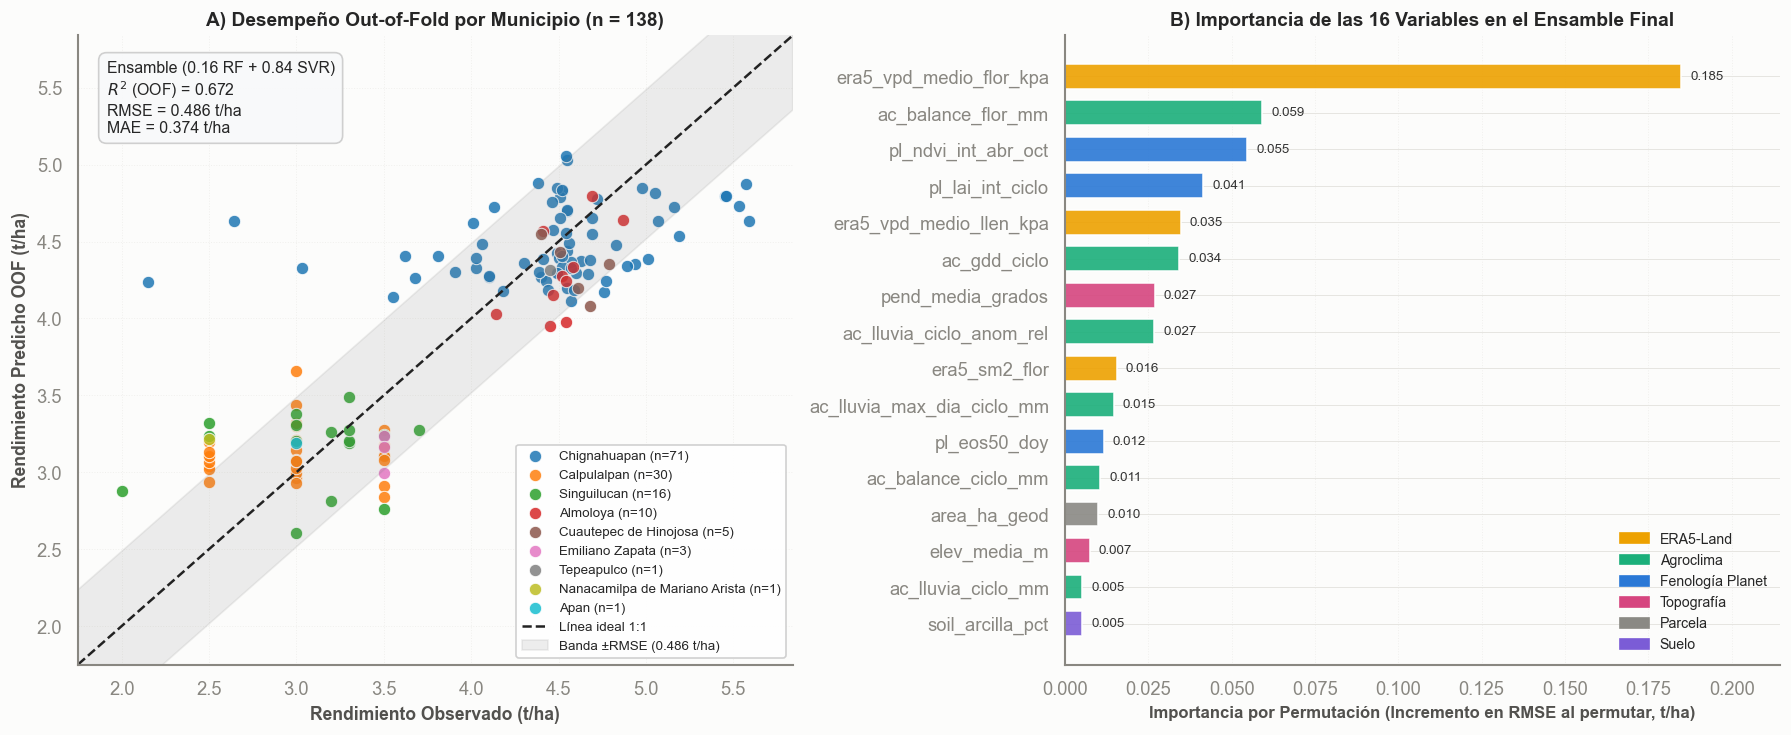

In [25]:
# Familia de cada variable predictora a partir de su prefijo
def familia_de(col):
    if col == 'area_ha_geod':
        return 'Parcela'
    if col.startswith('pl_'):
        return 'Fenología Planet'
    if col.startswith('s2_'):
        return 'Fenología Sentinel-2'
    if col.startswith('ac_'):
        return 'Agroclima'
    if col.startswith('era5_'):
        return 'ERA5-Land'
    if col.startswith('soil_'):
        return 'Suelo'
    return 'Topografía'

# Importancia por Permutación OOF del Ensamble (ponderada por el peso de cada modelo)
# Se usan clones para no alterar rf_final / svr_final, ya entrenados con las 138 parcelas
imp_ensamble_oof = np.zeros(len(vars_16))

# Función para calcular la importancia de las variables mediante Permutation Importance OOF del Ensamble
for train_idx, val_idx in cv_splits:
    X_tr, y_tr = df_train[vars_16].iloc[train_idx], y_train.iloc[train_idx]
    X_va, y_va = df_train[vars_16].iloc[val_idx], y_train.iloc[val_idx]

    rf_fold = clone(rf_final).fit(X_tr, y_tr)
    svr_fold = clone(svr_final).fit(X_tr, y_tr)

    perm_rf = permutation_importance(
        rf_fold, X_va, y_va, n_repeats=15, random_state=42,
        scoring='neg_root_mean_squared_error', n_jobs=-1
    )
    perm_svr = permutation_importance(
        svr_fold, X_va, y_va, n_repeats=15, random_state=42,
        scoring='neg_root_mean_squared_error', n_jobs=-1
    )

    imp_fold = mejor_w_16 * perm_rf.importances_mean + (1 - mejor_w_16) * perm_svr.importances_mean
    imp_ensamble_oof += imp_fold / len(cv_splits)

# Creamos un ranking final de importancia de las 16 variables en el Ensamble
serie_imp_final = pd.Series(imp_ensamble_oof, index=vars_16).sort_values(ascending=True)

# Gráfica de diagnóstico final: Observado vs. Predicho (OOF) y Importancia de Variables
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6.2), dpi=120)

# Panel A: Observado vs. Predicho (OOF) por municipio
municipios_orden = df_train['municipio'].value_counts().index.tolist()
cmap_mun = plt.get_cmap('tab10', len(municipios_orden))

# Ciclo para graficar cada municipio con un color distinto
for i, mun in enumerate(municipios_orden):
    mask = (df_train['municipio'] == mun).values
    ax1.scatter(
        y_train[mask], oof_ensamble_16[mask],
        label=f"{mun} (n={mask.sum()})", color=cmap_mun(i),
        s=55, alpha=0.85, edgecolors='white', linewidth=0.6
    )

# Configuración de límites y métricas para el panel A
lims = [min(y_train.min(), oof_ensamble_16.min()) - 0.25, max(y_train.max(), oof_ensamble_16.max()) + 0.25]
rmse_val = np.sqrt(mean_squared_error(y_train, oof_ensamble_16))
mae_val = mean_absolute_error(y_train, oof_ensamble_16)
r2_val = r2_score(y_train, oof_ensamble_16)

# Configuración de la gráfica Observado vs. Predicho (OOF)
ax1.plot(lims, lims, '--', color='#222222', lw=1.5, label='Línea ideal 1:1')
ax1.fill_between(
    lims, [l - rmse_val for l in lims], [l + rmse_val for l in lims],
    color='gray', alpha=0.13, label=f'Banda ±RMSE ({rmse_val:.3f} t/ha)'
)

# Configuración de texto con métricas del Ensamble
texto_metricas = (
    f"Ensamble ({mejor_w_16:.2f} RF + {1-mejor_w_16:.2f} SVR)\n"
    f"$R^2$ (OOF) = {r2_val:.3f}\n"
    f"RMSE = {rmse_val:.3f} t/ha\n"
    f"MAE = {mae_val:.3f} t/ha"
)
# Configuración de texto con métricas del Ensamble en la gráfica
ax1.text(
    0.04, 0.96, texto_metricas, transform=ax1.transAxes, fontsize=9.5, verticalalignment='top',
    bbox=dict(boxstyle='round,pad=0.5', facecolor='#F8F9FA', edgecolor='#CCCCCC', alpha=0.92)
)
# Configuración de ejes y leyenda para el panel A
ax1.set_xlim(lims)
ax1.set_ylim(lims)
ax1.set_xlabel("Rendimiento Observado (t/ha)", fontsize=10.5, fontweight='bold')
ax1.set_ylabel("Rendimiento Predicho OOF (t/ha)", fontsize=10.5, fontweight='bold')
ax1.set_title("A) Desempeño Out-of-Fold por Municipio (n = 138)", fontsize=11.5, fontweight='bold')
ax1.legend(loc='lower right', fontsize=8, frameon=True, facecolor='white', framealpha=0.9)
ax1.grid(True, linestyle=':', alpha=0.5)

# Panel B: Importancia de las 16 variables en el Ensamble
colores_barras = [COLOR_FAM[familia_de(c)] for c in serie_imp_final.index]
barras = ax2.barh(serie_imp_final.index, serie_imp_final.values, color=colores_barras, height=0.68, alpha=0.9)

# Configuración de etiquetas de importancia en las barras
max_imp = serie_imp_final.max()
for barra in barras:
    ancho = barra.get_width()
    ax2.text(ancho + max_imp * 0.015, barra.get_y() + barra.get_height() / 2,
             f"{ancho:.3f}", va='center', ha='left', fontsize=8, color='#333333')

# Configuración de leyenda para familias de variables
fams_presentes = list(dict.fromkeys([familia_de(c) for c in serie_imp_final.index[::-1]]))
handles_fam = [plt.Rectangle((0, 0), 1, 1, color=COLOR_FAM[f]) for f in fams_presentes]
ax2.legend(handles=handles_fam, labels=fams_presentes, frameon=False, fontsize=8.5, loc="lower right")

# Configuración de ejes y título para el panel B
ax2.set_xlim(0, max_imp * 1.16)
ax2.set_xlabel("Importancia por Permutación (Incremento en RMSE al permutar, t/ha)", fontsize=10, fontweight='bold')
ax2.set_title("B) Importancia de las 16 Variables en el Ensamble Final", fontsize=11.5, fontweight='bold')
ax2.grid(True, axis='x', linestyle=':', alpha=0.5)

# Ajuste de diseño y guardado de la gráfica final
plt.tight_layout()
plt.savefig(DATA_DIR / "Diagnostico_Final_Ensamble_16vars.png", dpi=300, bbox_inches='tight')
plt.show()

### Interpretaciones
El el gráfico A) podemos observar la capacidad predictiva de nuestro Modelo 5. Ensamble Final, la mayoria de los puntos se localizan cerca de la Linea Ideal (1:1) y dentro de un rango estable del RMSE.

En el gráfico B) podemoss observar varias cuestiones:
1. `era5_vpd_medio_flor_kpa` de la familia ERA5-Land es la variable más determinante, lo que nos dice que el déficit de presión de vapor (VPD) medio durante la etapa de floración es el factor ambiental que más condiciona el rendimiento final del cultivo.
2. Los factores climáticos y fenológicos secundario tambien determinaron el rendimiento, destacan variables como el balance hídrico en floración (`ac_balance_flor_mm` con 0.059) y el índice de vegetación en los meses de abril a octubre (`pl_ndvi_int_abr_oct` con 0.055).
3. Las familias de variables relacionadas de ERA5-Land (que nos dice clima y atmósfera) y Agroclima ocupan las posiciones más altas del ranking, por lo que, concluimos que las condiciones meteorológicas y hídricas superan en peso predictivo a las características estáticas del suelo o la topografía local, al menos para este conjunto de parcelas

## **4. Distribución de los 59 rendimientos predichos vs. entrenamiento**
Verificamos que las 59 observaciones predichas conservan la distribución bimodal(descubierta durante el EDA) de las 138 observaciones de entrenamiento.

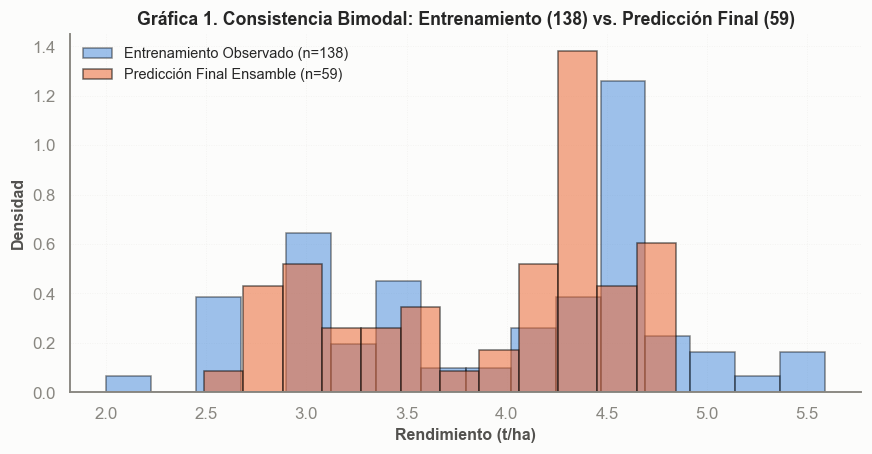

In [28]:
# Gráfica de consistencia bimodal: Entrenamiento (138) vs. Predicción Final (59)
fig, ax = plt.subplots(figsize=(8, 4.2), dpi=110)

# Configuración de histogramas para Entrenamiento y Predicción Final
ax.hist(y_train, bins=16, density=True, alpha=0.45, color=COLOR_CONJ['ENTRENAMIENTO'], edgecolor='black',
        label='Entrenamiento Observado (n=138)')
ax.hist(df_pred_59['rendimiento_pred_t_ha'], bins=12, density=True, alpha=0.55, color=COLOR_CONJ['PREDICCION'],
        edgecolor='black', label='Predicción Final Ensamble (n=59)')

# Configuración de ejes, título y leyenda para la gráfica de consistencia bimodal
ax.set_xlabel("Rendimiento (t/ha)", fontsize=10.5, fontweight='bold')
ax.set_ylabel("Densidad", fontsize=10.5, fontweight='bold')
ax.set_title("Gráfica 1. Consistencia Bimodal: Entrenamiento (138) vs. Predicción Final (59)", fontsize=11.5, fontweight='bold')
ax.legend(frameon=False, fontsize=9.5)
ax.grid(True, linestyle=':', alpha=0.4)

# Ajuste de diseño y guardado de la gráfica de consistencia bimodal
plt.tight_layout()
plt.show()

### Interpretaciones
En la gráfica 1 se pude observar la consistencia Bimodal que detectamos en la exploración de datos con los datos de entrenamiento. Que surja esta congruencia nos indica que nuestros valores estimados son consistentes con los datos empíricos.

## 5. Preguntas Bonus
- **Pregunta 1**. Índice Clave ¿Cuál importa más?

De acuerdo a nuestros resultados, el índice que importa más es Normalized Difference Vegetation Index (NVDI), es un indicador general de presencia, vigor y actividad de vegetación verde.
- **Pregunta 2**. Varible Climática ¿Cuál pesa más?

De acuerdo a los resultados obtenidos, la variable climática que pesa más `era5_vpd_medio_flor_kpa` de la familia ERA5-Land es la variable más determinante, lo que nos dice que el déficit de presión de vapor (VPD) medio durante la etapa de floración es el factor ambiental que más condiciona el rendimiento final del cultivo.
- **Pregunta 3**. Mejor combinación ¿Que variables funcionan mejor?

Con un $R^2$ de 0.672, un MAE de 0.374 t/ha y un RMSE de 0.4859 t/ha, la mejor combinanción de variables son:
1. `era5_vpd_medio_flor_kpa`: Déficit de Presión de Vapor medio (kPa) durante la etapa de floración. Mide qué tan seco está el aire y sirve para estimar el estrés hídrico atmosférico sobre las flores.
2. `ac_balance_flor_mm`: Representa el balance hídrico em floración
3. `pl_ndvi_int_abr_oct`: NDVI integrado (Normalized Difference Vegetation Index) acumulado o sumado entre los meses de abril y octubre. Representa la productividad verde acumulada de la vegetación en ese periodo.
4. `pl_lai_int_ciclo`: Índice de Área Foliar integrado (Leaf Area Index) acumulado a lo largo de todo el ciclo del cultivo. Mide la cantidad de superficie foliar verde disponible por unidad de suelo.
5. `era5_vpd_medio_llen_kpa`: Déficit de Presión de Vapor medio (kPa) durante la etapa de llenado del grano.
6. `ac_gdd_ciclo`: Grados Día de Desarrollo acumulados (Growing Degree Days) durante todo el ciclo. Mide la acumulación de energía térmica (calor) disponible para que el cultivo complete sus fases fenológicas.
7. `pend_media_grados`: Pendiente media del terreno, medida en grados.
8. `ac_lluvia_ciclo_anom_rel`: Anomalía relativa de la lluvia del ciclo. Mide qué tan por encima o por debajo de lo normal (histórico) estuvo la precipitación del ciclo, expresada de forma proporcional o porcentual.
9. `era5_sm2_flor`: Humedad del suelo en la capa 2 (Soil Moisture Layer 2) según el modelo ERA5 durante la etapa de floración. Generalmente representa la humedad en la zona radicular media o profunda.
10. `ac_lluvia_max_dia_ciclo_mm`: Precipitación máxima en un solo día (mm) ocurrida a lo largo de todo el ciclo del cultivo (indica eventos de lluvia extrema o tormentas).
11. `pl_eos50_doy`: Fin de temporada al 50% (End of Season 50%), expresado como el Día del Año (Day of Year, DOY, un número entero del 1 al 365 que indica el día exacto en que el cultivo madura o termina su ciclo según índices de vegetación).
12. `ac_balance_ciclo_mm`: Balance hídrico acumulado total (mm) durante todo el ciclo del cultivo.
13. `area_ha_geod`: Área geodésica (hectáreas) de la parcela o polígono de estudio calculada tomando en cuenta la curvatura de la Tierra.
14. `elev_media_m`: Elevación o altitud media (metros) sobre el nivel del mar de la zona o parcela.
15. `ac_lluvia_ciclo_mm`: Lluvia acumulada total (mm) registrada durante todo el ciclo del cultivo.
16. `soil_arcilla_pct`: Porcentaje de arcilla en la composición textural del suelo (proporción de partículas minerales $< 2\,\mu\text{m}$).

# Exportar datasets

Se generan las predicciones de los 6 modelos (OOF para las 138 parcelas de entrenamiento e inferencia para las 59 de predicción):

1. Modelo base: Random Forest Original (62 variables predictoras, KFold simple) (se reproduce aquí con `dataset_62vars.csv`)
2. Modelo 1: Random Forest con Permutation Importance Out-of-Fold (OOF) (19 variables predictoras)
3. Modelo 2: Random Forest con GridSearchCV  (19 variables predictoras)
4. Modelo de prueba: SVR con StandardScaler y kernel RBF (19 variables predictoras)
5. Modelo 3: Ensamble con Blending: 0.27 Random Forest + 0.73 Support Vectorial Regression (SVR) (19 variables predictoras)
6. Modelo 4: Ensamble con Blending + Selección de Variables con (Sequential Backward Elimination) (16 variables predictoras) (paso intermedio, sin predicciones propias)
7. Modelo 5: Ensamble Final tras seleccion de variables SBE (16 vars)

Nota:

El Modelo Base usa las 62 predictoras originales: las 11 redundantes Greedy no están en `dataset_modelo.csv`, así que se leen de `dataset_62vars.csv` (exportado de la tabla `matriz_caracteristicas` de Supabase, con el orden de columnas de la tabla).

In [27]:
# Las 62 predictoras originales (id_poligono + 62 columnas en el orden de la tabla de Supabase)
df_62 = pd.read_csv(DATA_DIR / 'dataset_62vars.csv')
vars_62 = [c for c in df_62.columns if c != 'id_poligono']

assert len(vars_62) == 62 and set(cols_predictoras) <= set(vars_62)
assert [c for c in vars_62 if c in cols_predictoras] == cols_predictoras, 'Orden distinto al de cols_predictoras'

# Matrices de 62 variables alineadas fila a fila con df_train / df_pred
X62 = df_62.set_index('id_poligono')[vars_62]
X62_train = X62.loc[df_train['id_poligono']].set_index(df_train.index)
X62_pred = X62.loc[df_pred['id_poligono']].set_index(df_pred.index)

# Las 51 predictoras de Supabase deben coincidir con dataset_modelo.csv
assert np.allclose(X62_train[cols_predictoras].values, df_train[cols_predictoras].values)
assert np.allclose(X62_pred[cols_predictoras].values, df_pred[cols_predictoras].values)
print(f"X62_train: {X62_train.shape} | X62_pred: {X62_pred.shape} | 51 predictoras idénticas a dataset_modelo.csv")

X62_train: (138, 62) | X62_pred: (59, 62) | 51 predictoras idénticas a dataset_modelo.csv


In [ ]:
# 
vars_19 = list(vars_optimas)

# Modelo base: Random Forest Original (62 variables predictoras, KFold simple)
rf_m1 = RandomForestRegressor(n_estimators=500, min_samples_leaf=3, random_state=42, n_jobs=-1)
cv_kfold_simple = KFold(n_splits=5, shuffle=True, random_state=42)
oof_m1 = cross_val_predict(rf_m1, X62_train, y_train, cv=cv_kfold_simple, n_jobs=-1)
rf_m1.fit(X62_train, y_train)
pred59_m1 = rf_m1.predict(X62_pred)

# Modelo 1: Random Forest con Permutation Importance Out-of-Fold (OOF) (19 variables predictoras)
rf_m2 = RandomForestRegressor(
    n_estimators=500, max_features='sqrt', min_samples_leaf=3,
    max_depth=6, max_samples=0.8, random_state=42, n_jobs=-1
)
oof_m2 = cross_val_predict(rf_m2, df_train[vars_19], y_train, cv=cv_splits, n_jobs=-1)
rf_m2.fit(df_train[vars_19], y_train)
pred59_m2 = rf_m2.predict(df_pred[vars_19])

# Modelo 2: Random Forest con GridSearchCV  (19 variables predictoras)
oof_m3 = cross_val_predict(best_rf, df_train[vars_19], y_train, cv=cv_splits, n_jobs=-1)
best_rf.fit(df_train[vars_19], y_train)
pred59_m3 = best_rf.predict(df_pred[vars_19])

# Modelo 3: Ensamble con Blending: 0.27 Random Forest + 0.73 Support Vectorial Regression (SVR) (19 variables predictoras)
oof_m4 = cross_val_predict(best_svr, df_train[vars_19], y_train, cv=cv_splits, n_jobs=-1)
best_svr.fit(df_train[vars_19], y_train)
pred59_m4 = best_svr.predict(df_pred[vars_19])

# Modelo 4: Ensamble con Blending + Selección de Variables con (Sequential Backward Elimination) (16 variables predictoras)
oof_m5 = mejor_w * oof_m3 + (1 - mejor_w) * oof_m4
pred59_m5 = mejor_w * pred59_m3 + (1 - mejor_w) * pred59_m4

# Modelo 5: Ensamble Final tras seleccion de variables SBE (16 vars)
oof_m6 = oof_ensamble_16
pred59_m6 = df_pred_59['rendimiento_pred_t_ha'].values

print("Métricas OOF de los 6 Modelos (138 parcelas)")
imprimir_metricas("Modelo base: Random Forest Original (62 vars, KFold)", y_train, oof_m1)
imprimir_metricas("Modelo 1: Random Forest con Permutation Importance Out-of-Fold (OOF)", y_train, oof_m2)
imprimir_metricas("Modelo 2: Random Forest con GridSearchCV  (19 variables predictoras)", y_train, oof_m3)
imprimir_metricas("Modelo 3: Ensamble con Blending: 0.27 Random Forest + 0.73 SVR", y_train, oof_m4)
imprimir_metricas(f"M5 Ensamble ({mejor_w:.2f} RF + {1-mejor_w:.2f} SVR)", y_train, oof_m5)
imprimir_metricas(f"M6 Ensamble SBE ({mejor_w_16:.2f} RF + {1-mejor_w_16:.2f} SVR)", y_train, oof_m6)

# Archivo 1: comparacion_rendimientos.csv
cols_modelos = {
    'M1_RF_Original_62vars': (oof_m1, pred59_m1),
    'M2_RF_Subconjunto_Optimo_19vars': (oof_m2, pred59_m2),
    'M3_RF_Optimizado_GridSearch_19vars': (oof_m3, pred59_m3),
    'M4_SVR_RBF_19vars': (oof_m4, pred59_m4),
    'M5_Ensamble_19vars_27RF_73SVR': (oof_m5, pred59_m5),
    'M6_Ensamble_Final_SBE_16vars': (oof_m6, pred59_m6),
}

# Función para crear la tabla base con id_poligono, estado, municipio, conjunto y rendimiento
def tabla_base(d, rend):
    return pd.DataFrame({
        'id_poligono': d['id_poligono'].values,
        'estado': d['estado'].values,
        'municipio': d['municipio'].values,
        'conjunto': d['conjunto'].values,
        'rendimiento_t_ha': rend,
    })

# Creamos los DataFrames de comparación de rendimiento para entrenamiento y predicción
df_comp_train = tabla_base(df_train, y_train.values)
df_comp_pred = tabla_base(df_pred, np.nan)
for nombre, (oof, p59) in cols_modelos.items():
    df_comp_train[nombre] = oof
    df_comp_pred[nombre] = p59

# Concatenamos los DataFrames de entrenamiento y predicción para generar el archivo final
comparacion_rendimientos = pd.concat([df_comp_train, df_comp_pred], ignore_index=True)
comparacion_rendimientos.round(4).to_csv(DATA_DIR / "comparacion_rendimientos.csv", index=False, encoding='utf-8-sig')
print(f"\n1) 'comparacion_rendimientos.csv' -> Filas: {len(comparacion_rendimientos)} | Columnas: {len(comparacion_rendimientos.columns)}")

# Archivo 2: dataset_rendimientos_estimados.csv
dataset_rendimientos_estimados = comparacion_rendimientos[['id_poligono', 'estado', 'municipio', 'conjunto', 'rendimiento_t_ha']].copy()

# Se conservan los 138 valores reales y se rellenan los 59 nulos con el Modelo 6
mask_pred = dataset_rendimientos_estimados['rendimiento_t_ha'].isna()
assert (dataset_rendimientos_estimados.loc[mask_pred, 'conjunto'] == 'PREDICCION').all() and mask_pred.sum() == 59
dataset_rendimientos_estimados.loc[mask_pred, 'rendimiento_t_ha'] = comparacion_rendimientos.loc[mask_pred, 'M6_Ensamble_Final_SBE_16vars']

# Guardamos el archivo final de predicción con los 138 valores reales y los 59 imputados
dataset_rendimientos_estimados.round(4).to_csv(DATA_DIR / "dataset_rendimientos_estimados.csv", index=False, encoding='utf-8-sig')
print(f"2) 'dataset_rendimientos_estimados.csv' -> Filas totales: {len(dataset_rendimientos_estimados)} "
      f"(Entrenamiento conservadas: {(~mask_pred).sum()}, Predicción imputadas: {mask_pred.sum()})")
print("   Valores nulos restantes en rendimiento_t_ha:", dataset_rendimientos_estimados['rendimiento_t_ha'].isna().sum())

Métricas OOF de los 6 MODELOS (138 parcelas) ===
M1 Random Forest Original (62 vars, KFold) -> R²: 0.541 | MAE: 0.433 | RMSE: 0.575 t/ha
M2 Random Forest Subconjunto Óptimo (19 vars, StratifiedKFold) -> R²: 0.586 | MAE: 0.416 | RMSE: 0.546 t/ha
M3 Random Forest Optimizado (GridSearch, 19 vars) -> R²: 0.601 | MAE: 0.401 | RMSE: 0.536 t/ha
M4 SVR RBF (19 vars)               -> R²: 0.638 | MAE: 0.390 | RMSE: 0.510 t/ha
M5 Ensamble (0.27 RF + 0.73 SVR)   -> R²: 0.644 | MAE: 0.386 | RMSE: 0.506 t/ha
M6 Ensamble SBE (0.16 RF + 0.84 SVR) -> R²: 0.672 | MAE: 0.374 | RMSE: 0.486 t/ha

1) 'comparacion_rendimientos.csv' -> Filas: 197 | Columnas: 11
2) 'dataset_rendimientos_estimados.csv' -> Filas totales: 197 (Entrenamiento conservadas: 138, Predicción imputadas: 59)
   Valores nulos restantes en rendimiento_t_ha: 0
